# How Much Does a Better Forecast Help?

This companion revisits battery arbitrage with uncertain prices. At each decision hour, we build scenarios only from older prices, implement one action, observe the realized price, and replan.

The notebook separates three questions:

* What is the value of perfect information at one forecast origin?
* Does modeling forecast uncertainty improve the first action?
* How do the policies perform out of sample in a rolling backtest?

## Learning goals

* Put shared first-stage decisions on the root model and recourse on scenario `Block`s.
* Distinguish a two-stage approximation from a multistage scenario tree.
* Compute RP, EEV, WS, VSS, and EVPI with the profit convention.
* Prevent simultaneous charging and discharging, including at negative prices.
* Compare expected-value, stochastic, risk-averse, and perfect-forecast policies.

In [1]:
# Install course dependencies before importing Pyomo on Colab.
import sys

if "google.colab" in sys.modules:
    !wget "https://raw.githubusercontent.com/ndcbe/optimization/main/notebooks/helper.py"
    import helper

    helper.easy_install()
else:
    sys.path.insert(0, "../")
    import helper

helper.set_plotting_style()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyomo.environ as pyo

SOLVER = pyo.SolverFactory("appsi_highs")
assert SOLVER.available(
    exception_flag=False
), "Install HiGHS before running this notebook."

## Data and information pattern

The repository supplies a historical CAISO day-ahead price series in `Prices_DAM_ALTA2G_7_B1.csv`. The teaching model treats each entry as one hour. This is an illustrative sequential-information experiment, not a reconstruction of day-ahead auction timing: in an actual day-ahead schedule, the next day’s clearing prices are not revealed one hour at a time.

At decision hour $t$:

* the seven scenarios are 24-hour windows beginning at the same hour on the previous seven days;
* every scenario ends at or before $t$;
* the realized window beginning at $t$ is reserved for evaluation; and
* an oracle policy may use that window only as an unattainable benchmark.

This historical ensemble is transparent, not a claim of forecasting state of the art.
See [CAISO’s market description](https://www.caiso.com/market-operations/products-services) for actual day-ahead timing.


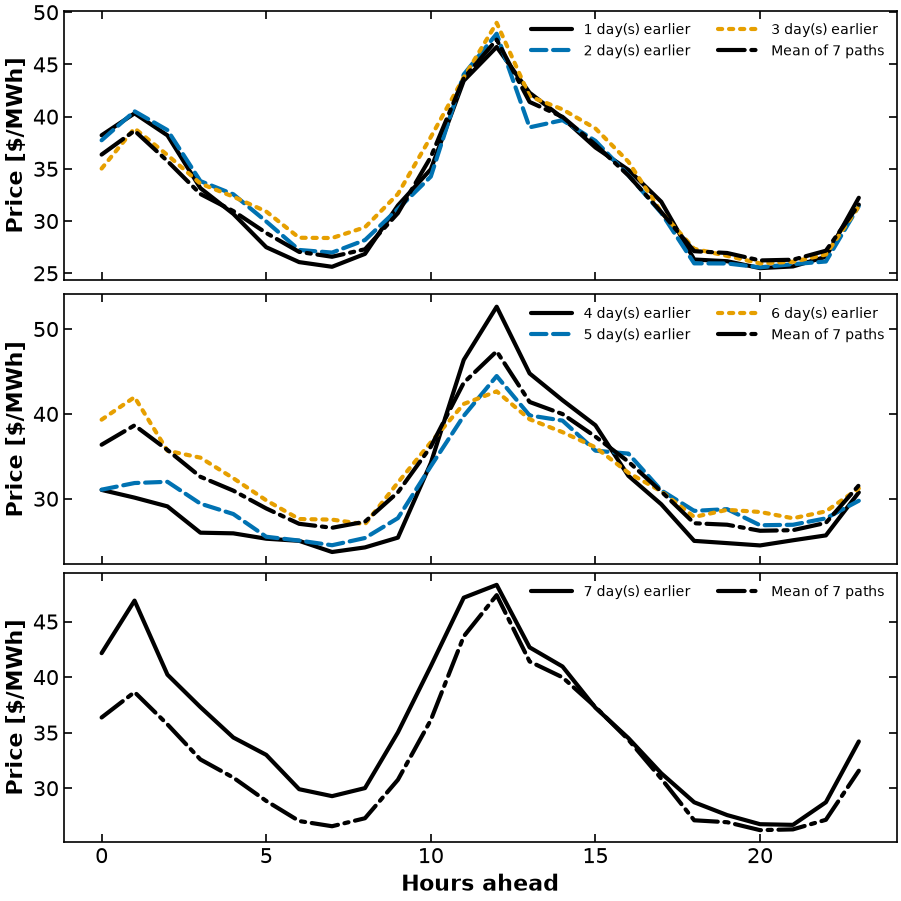

In [2]:
prices = pd.read_csv("../data/Prices_DAM_ALTA2G_7_B1.csv", names=["price"])[
    "price"
].to_numpy(float)

HORIZON = 24
N_SCENARIOS = 7
FIRST_BACKTEST_HOUR = 678
BACKTEST_HOURS = 48

assert FIRST_BACKTEST_HOUR >= N_SCENARIOS * 24
assert FIRST_BACKTEST_HOUR + BACKTEST_HOURS + HORIZON <= len(prices)


def backcast_scenarios(
    price_history, decision_hour, horizon=HORIZON, n_scenarios=N_SCENARIOS
):
    # Aligned historical price paths available by decision_hour.
    starts = [decision_hour - 24 * day for day in range(1, n_scenarios + 1)]
    scenarios = np.vstack([price_history[start : start + horizon] for start in starts])
    assert max(start + horizon for start in starts) <= decision_hour
    return scenarios


scenarios = backcast_scenarios(prices, FIRST_BACKTEST_HOUR)
# Small multiples keep no more than three historical paths on each axes.
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True, layout="constrained")
for group, ax in enumerate(axes):
    for k in range(group * 3, min((group + 1) * 3, len(scenarios))):
        ax.plot(
            scenarios[k],
            linestyle=["-", "--", ":"][k % 3],
            label=f"{k + 1} day(s) earlier",
        )
    ax.plot(
        scenarios.mean(axis=0), color="black", linestyle="-.", label="Mean of 7 paths"
    )
    ax.set_ylabel("Price [$/MWh]")
    ax.legend(fontsize=10, ncol=2)
axes[-1].set_xlabel("Hours ahead")
plt.show()

## Two-stage scenario-block model

Battery assumptions:

* 1-hour time steps;
* 1 MW charge and discharge limits;
* 4 MWh energy capacity;
* 92% one-way efficiency; and
* terminal energy equals initial energy over each planning horizon.

The root variables are the action implemented now. Every scenario block contains later recourse decisions and its own price path. Only the first action is nonanticipative, so this is a **two-stage approximation**: after hour 0, each scenario acts as though its entire path were revealed. A true multistage model would need a scenario tree and nonanticipativity at every shared history.

Binary operating modes prevent simultaneous charge and discharge. This matters when prices are negative: without the modes, artificial cycling losses can become profitable.

In [3]:
POWER_CAPACITY = 1.0  # MW
ENERGY_CAPACITY = 4.0  # MWh
EFFICIENCY = 0.92


def build_battery_model(
    price_scenarios,
    initial_energy,
    terminal_energy=None,
    risk_weight=0.0,
    cvar_confidence=0.90,
):
    """Build a two-stage MILP with one-hour steps and equal scenario weights.

    Power is MW, energy MWh, prices dollars/MWh; all profit terms are dollars.
    Only hour zero is shared. Later actions anticipate each full scenario path.
    Args: price_scenarios [$/MWh], initial/terminal energy [MWh],
        risk_weight [0, 1], and cvar_confidence (0, 1).
    Returns: a fresh Pyomo ConcreteModel with a profit-maximizing objective.
    """
    if not 0 <= risk_weight <= 1 or not 0 < cvar_confidence < 1:
        raise ValueError("Require weight in [0, 1] and confidence in (0, 1)")
    price_scenarios = np.asarray(price_scenarios, dtype=float)
    n_scenarios, horizon = price_scenarios.shape
    terminal_energy = initial_energy if terminal_energy is None else terminal_energy

    m = pyo.ConcreteModel()
    m.S = pyo.RangeSet(0, n_scenarios - 1)
    m.T = pyo.RangeSet(0, horizon - 1)
    m.probability = pyo.Param(m.S, initialize=1 / n_scenarios)

    # Shared first-stage action.
    m.first_charge = pyo.Var(bounds=(0, POWER_CAPACITY))
    m.first_discharge = pyo.Var(bounds=(0, POWER_CAPACITY))
    m.first_mode = pyo.Var(domain=pyo.Binary)
    m.first_charge_limit = pyo.Constraint(
        expr=m.first_charge <= POWER_CAPACITY * m.first_mode
    )
    m.first_discharge_limit = pyo.Constraint(
        expr=m.first_discharge <= POWER_CAPACITY * (1 - m.first_mode)
    )

    def scenario_rule(block, scenario):
        block.price = pyo.Param(
            m.T, initialize=lambda block, hour: price_scenarios[scenario, hour]
        )
        block.charge = pyo.Var(m.T, domain=pyo.NonNegativeReals)
        block.discharge = pyo.Var(m.T, domain=pyo.NonNegativeReals)
        block.energy = pyo.Var(m.T, bounds=(0, ENERGY_CAPACITY))
        block.mode = pyo.Var(m.T, domain=pyo.Binary)

        @block.Constraint(m.T)
        def charge_limit(b, hour):
            return b.charge[hour] <= POWER_CAPACITY * b.mode[hour]

        @block.Constraint(m.T)
        def discharge_limit(b, hour):
            return b.discharge[hour] <= POWER_CAPACITY * (1 - b.mode[hour])

        # A one-hour step converts MW to MWh; efficiency acts on each flow.
        @block.Constraint(m.T)
        def energy_balance(b, hour):
            previous = initial_energy if hour == 0 else b.energy[hour - 1]
            return b.energy[hour] == (
                previous + EFFICIENCY * b.charge[hour] - b.discharge[hour] / EFFICIENCY
            )

        block.terminal = pyo.Constraint(
            expr=block.energy[horizon - 1] == terminal_energy
        )
        # Linking every scenario to root actions enforces nonanticipativity.
        block.link_charge = pyo.Constraint(expr=block.charge[0] == m.first_charge)
        block.link_discharge = pyo.Constraint(
            expr=block.discharge[0] == m.first_discharge
        )
        block.link_mode = pyo.Constraint(expr=block.mode[0] == m.first_mode)
        block.profit = pyo.Expression(
            expr=sum(
                block.price[hour] * (block.discharge[hour] - block.charge[hour])
                for hour in m.T
            )
        )

    m.scenario = pyo.Block(m.S, rule=scenario_rule)
    m.expected_profit = pyo.Expression(
        expr=sum(m.probability[s] * m.scenario[s].profit for s in m.S)
    )

    # Lower-tail PROFIT CVaR is minus upper-tail CVaR of negative profit.
    if risk_weight > 0:
        # An optimal threshold may be nonunique; do not call it unique VaR.
        m.profit_var = pyo.Var()
        for s in m.S:
            block = m.scenario[s]
            block.shortfall = pyo.Var(domain=pyo.NonNegativeReals)
            block.shortfall_constraint = pyo.Constraint(
                expr=block.shortfall >= m.profit_var - block.profit
            )
        m.lower_tail_cvar = pyo.Expression(
            expr=m.profit_var
            - sum(m.probability[s] * m.scenario[s].shortfall for s in m.S)
            / (1 - cvar_confidence)
        )
        m.objective = pyo.Objective(
            expr=(1 - risk_weight) * m.expected_profit
            + risk_weight * m.lower_tail_cvar,
            sense=pyo.maximize,
        )
    else:
        m.objective = pyo.Objective(expr=m.expected_profit, sense=pyo.maximize)
    return m


def solve(model):
    result = SOLVER.solve(model)
    assert pyo.check_optimal_termination(result), result.solver.termination_condition
    return model


def first_action(model):
    return (
        float(pyo.value(model.first_charge)),
        float(pyo.value(model.first_discharge)),
    )

## Value of information at one forecast origin

Using the profit convention:

* **RP** solves the two-stage recourse problem;
* **EEV** fixes the expected-value model's first action, then evaluates its recourse;
* **WS** averages independent perfect-information solutions;
* $\mathrm{VSS}=RP-EEV$; and
* $\mathrm{EVPI}=WS-RP$.

For a maximization problem, $WS\ge RP\ge EEV$ up to solver tolerance. Hour 678 is a fixed illustrative origin with nontrivial, but modest, value-of-information differences; the magnitudes depend on the scenario set. The theoretical information-value ordering still holds for every consistently defined, feasibly solved model; realized rolling-policy profits need not have that ordering.

In [4]:
def information_metrics(price_scenarios, initial_energy=2.0):
    stochastic = solve(build_battery_model(price_scenarios, initial_energy))
    rp = float(pyo.value(stochastic.expected_profit))

    mean_path = np.asarray(price_scenarios).mean(axis=0, keepdims=True)
    expected_value_model = solve(build_battery_model(mean_path, initial_energy))
    expected_value_action = first_action(expected_value_model)

    # Freeze only the implemented action; recourse is re-optimized.
    eev_model = build_battery_model(price_scenarios, initial_energy)
    eev_model.first_charge.fix(expected_value_action[0])
    eev_model.first_discharge.fix(expected_value_action[1])
    eev = float(pyo.value(solve(eev_model).expected_profit))

    # Oracle plans may choose different first actions in different scenarios.
    ws_values = []
    for s in range(np.asarray(price_scenarios).shape[0]):
        perfect_model = solve(
            build_battery_model(price_scenarios[s : s + 1], initial_energy)
        )
        ws_values.append(float(pyo.value(perfect_model.expected_profit)))
    ws = float(np.mean(ws_values))

    # HiGHS' MIP tolerance can leave sub-millidollar differences.
    tolerance = 1e-3
    assert ws + tolerance >= rp >= eev - tolerance
    return {
        "RP": rp,
        "EEV": eev,
        "WS": ws,
        "VSS": rp - eev,
        "EVPI": ws - rp,
    }


metrics = information_metrics(scenarios)
pd.Series(metrics, name="profit [$]").to_frame().round(2)

,profit [$]
RP,52.15
EEV,52.10
WS,52.59
VSS,0.05
EVPI,0.44


## Scenario-count and risk sensitivity

VSS and EVPI are properties of a model and scenario set, not universal constants. Recompute them as older backcast days are added.

For a risk-averse comparison, maximize a 50--50 blend of expected profit and the lower-tail 90% CVaR of profit. The lower-tail form rewards policies whose poor-scenario profit is less severe.

In [5]:
scenario_count_results = []
for count in [3, 5, 7]:
    count_metrics = information_metrics(scenarios[:count])
    scenario_count_results.append({"scenarios": count, **count_metrics})
pd.DataFrame(scenario_count_results).set_index("scenarios").round(2)

,RP,EEV,WS,VSS,EVPI
scenarios,,,,,
3,53.68,53.68,53.68,0.00,0.00
5,53.94,53.94,54.15,0.00,0.22
7,52.15,52.10,52.59,0.05,0.44


In [6]:
risk_neutral_model = solve(build_battery_model(scenarios, initial_energy=2.0))
risk_averse_model = solve(
    build_battery_model(
        scenarios,
        initial_energy=2.0,
        risk_weight=0.5,
        cvar_confidence=0.90,
    )
)


def scenario_profits(model):
    return np.array([pyo.value(model.scenario[s].profit) for s in model.S])


comparison = pd.DataFrame(
    {
        "risk neutral": [
            *first_action(risk_neutral_model),
            scenario_profits(risk_neutral_model).mean(),
            scenario_profits(risk_neutral_model).min(),
        ],
        "risk averse": [
            *first_action(risk_averse_model),
            scenario_profits(risk_averse_model).mean(),
            scenario_profits(risk_averse_model).min(),
        ],
    },
    index=[
        "first charge [MW]",
        "first discharge [MW]",
        "mean profit [$]",
        "Lower-tail CVaR(0.9) [$]",
    ],
)
comparison.round(2)

,risk neutral,risk averse
first charge [MW],0.00,0.00
first discharge [MW],0.55,0.80
mean profit [$],52.15,52.11
Lower-tail CVaR(0.9) [$],39.89,40.30


## Closed-loop backtest

At each hour, every implementable policy uses only the backcast ensemble available at that hour. It implements the shared first action, then updates energy and cash with the realized price.

The oracle instead uses the actual next 24 prices. It deliberately leaks future information and is included only as a perfect-forecast benchmark. Because rolling policies can finish with different energy, compare cash **plus terminal inventory value**, using the last observed price as a transparent salvage-price approximation.

In [7]:
def run_backtest(policy, price_history, first_hour, n_hours, initial_energy=2.0):
    energy = initial_energy
    cash = 0.0
    rows = []

    for hour in range(first_hour, first_hour + n_hours):
        backcasts = backcast_scenarios(price_history, hour)
        if policy == "stochastic":
            model = build_battery_model(backcasts, energy)
        elif policy == "expected value":
            model = build_battery_model(backcasts.mean(axis=0, keepdims=True), energy)
        elif policy == "risk averse":
            model = build_battery_model(
                backcasts, energy, risk_weight=0.5, cvar_confidence=0.90
            )
        elif policy == "perfect forecast":
            realized_path = price_history[hour : hour + HORIZON][None, :]
            model = build_battery_model(realized_path, energy)
        else:
            raise ValueError(policy)

        # Execute ONLY the first action. Rebuild next hour using observed data.
        charge, discharge = first_action(solve(model))
        assert min(charge, discharge) <= 1e-7
        energy += EFFICIENCY * charge - discharge / EFFICIENCY
        assert -1e-7 <= energy <= ENERGY_CAPACITY + 1e-7
        cash += price_history[hour] * (discharge - charge)
        rows.append(
            {
                "hour": hour,
                "price": price_history[hour],
                "charge": charge,
                "discharge": discharge,
                "energy": energy,
                "cash": cash,
            }
        )
    return pd.DataFrame(rows)


policies = ["expected value", "stochastic", "risk averse", "perfect forecast"]
runs = {
    policy: run_backtest(policy, prices, FIRST_BACKTEST_HOUR, BACKTEST_HOURS)
    for policy in policies
}

terminal_price = prices[FIRST_BACKTEST_HOUR + BACKTEST_HOURS - 1]
summary = pd.DataFrame(
    {
        policy: [
            run.cash.iloc[-1],
            run.energy.iloc[-1],
            EFFICIENCY * terminal_price * run.energy.iloc[-1],
            run.cash.iloc[-1] + EFFICIENCY * terminal_price * run.energy.iloc[-1],
        ]
        for policy, run in runs.items()
    },
    index=[
        "realized cash [$]",
        "final energy [MWh]",
        "terminal inventory value [$]",
        "cash + terminal inventory value [$]",
    ],
)
summary.round(2)

,expected value,stochastic,risk averse,perfect forecast
realized cash [$],24.88,27.49,37.54,138.04
final energy [MWh],4.00,4.00,3.58,0.32
terminal inventory value [$],104.95,104.95,93.95,8.40
cash + terminal inventory value [$],129.82,132.43,131.49,146.44


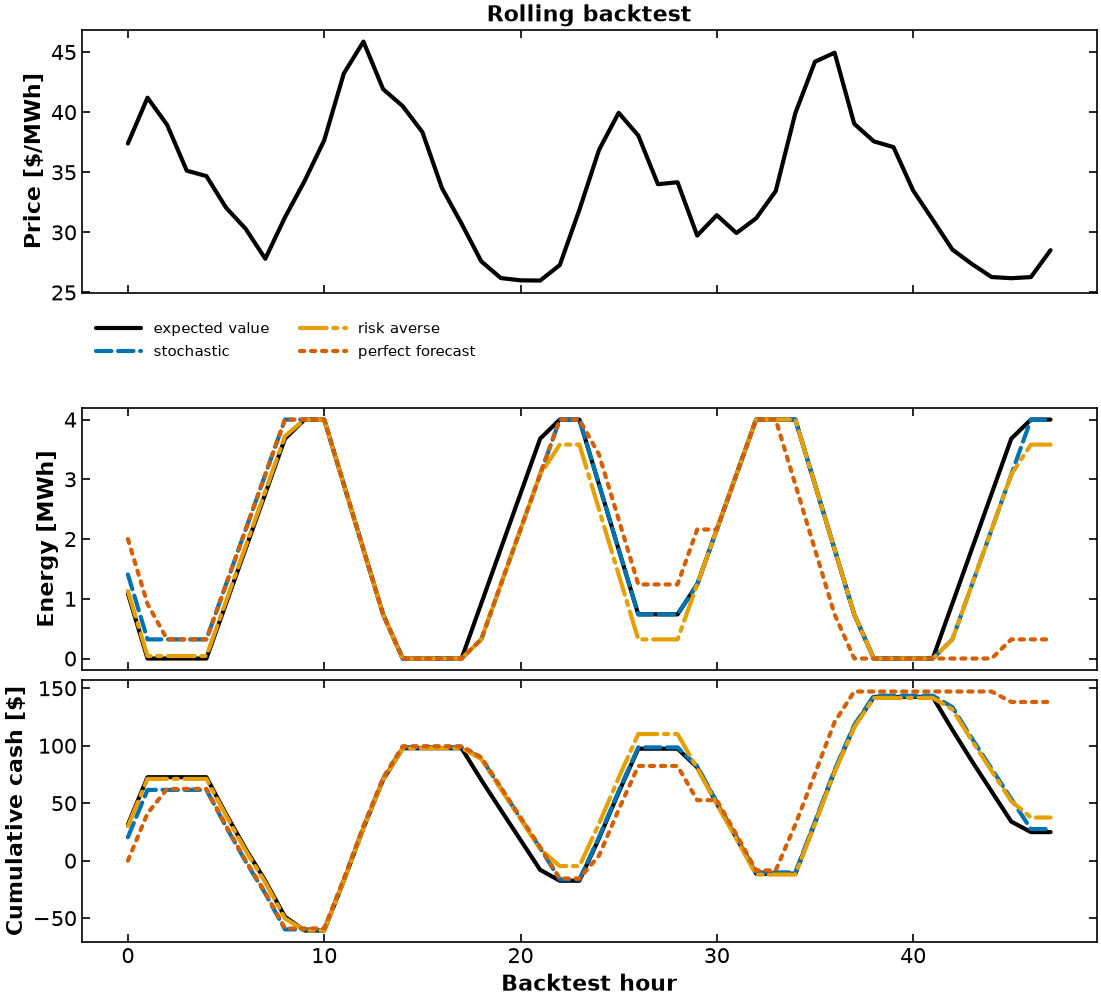

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True, layout="constrained")
hours = np.arange(BACKTEST_HOURS)
styles = {
    "expected value": ("black", "-"),
    "stochastic": ("#0072B2", "--"),
    "risk averse": ("#E69F00", "-."),
    "perfect forecast": ("#D55E00", ":"),
}

axes[0].plot(hours, runs["stochastic"].price, color="black")
axes[0].set(ylabel="Price [$/MWh]", title="Rolling backtest")

for policy in policies:
    color, linestyle = styles[policy]
    axes[1].plot(
        hours, runs[policy].energy, color=color, linestyle=linestyle, label=policy
    )
    axes[2].plot(
        hours, runs[policy].cash, color=color, linestyle=linestyle, label=policy
    )

axes[1].set_ylabel("Energy [MWh]")
axes[2].set(xlabel="Backtest hour", ylabel="Cumulative cash [$]")
axes[1].legend(ncol=2, fontsize=11, loc="upper left", bbox_to_anchor=(0, 1.38))

plt.show()

## Interpret

1. Why can EVPI be positive when VSS is small?
2. How does scenario count change the metrics? Is the change monotone?
3. Does the risk-averse first action improve the lower tail, and what happens to mean profit?
4. Why is cash alone an unfair comparison when policies finish with different stored energy?
5. How much inventory-adjusted value separates the implementable policies from the oracle in this 48-hour sample?
6. Which assumption would you improve first: scenario construction, terminal valuation, battery degradation, market timing, or the two-stage information pattern?

One short backtest is evidence, not proof. A serious forecast comparison needs repeated out-of-sample windows and must charge every policy the same battery and market costs.

(weekly-commitment)=
## Fixed weekly ensemble: commit one hour or one day

This separate experiment extends the introductory battery LP. It holds the scenario set fixed and changes how many actions must be chosen before the price path is revealed. It is **not a forecast backtest**: weeks are sampled from the whole historical year, without a forecast origin or a train/test split. The rolling experiment above uses past-only scenarios, a different efficiency, and binary operating modes. Its profits cannot be compared directly with the weekly results below.

Let $\mathcal S=\{1,\ldots,S\}$, $\mathcal T=\{1,\ldots,T\}$, and $\mathcal C=\{1,\ldots,K\}$, where $1\le K\le T$. Scenario $s$ has known hourly prices $p_{s,t}$ and probability $\pi_s=1/S$. Charge $c_{s,t}$ and discharge $d_{s,t}$ are in MW; end-of-hour energy $E_{s,t}$ is in MWh. Shared decisions $\widehat c_t,\widehat d_t$ commit the first $K$ hours in every scenario:

$$
\begin{aligned}
\max\quad &\sum_{s\in\mathcal S}\pi_s\sum_{t\in\mathcal T}p_{s,t}(d_{s,t}-c_{s,t})\Delta t\\
\text{s.t.}\quad&E_{s,t}=E_{s,t-1}+\left(\sqrt\eta\,c_{s,t}-d_{s,t}/\sqrt\eta\right)\Delta t&&s\in\mathcal S,t\in\mathcal T,\\
&E_{s,0}=E_0,\quad E_{s,T}=E_0&&s\in\mathcal S,\\
&c_{s,t}=\widehat c_t,\quad d_{s,t}=\widehat d_t&&s\in\mathcal S,t\in\mathcal C,\\
&0\le c_{s,t}\le1,\quad0\le d_{s,t}\le1,\quad0\le E_{s,t}\le4&&s\in\mathcal S,t\in\mathcal T,\\
&0\le\widehat c_t\le1,\quad0\le\widehat d_t\le1&&t\in\mathcal C.
\end{aligned}
$$

Here $E_{s,0}$ is the given parameter $E_0=0$, not an additional variable. Set $\Delta t=1$ h and **round-trip** efficiency $\eta=0.88$, so each flow uses $\sqrt{0.88}$. The shared commitment is the only nonanticipativity condition: after hour $K$, recourse acts as though the entire remaining week were known. This is a two-stage approximation, not an hourly scenario tree or an operational market-timing model.

There are $3ST+2K$ continuous variables, $S(T+1+2K)$ equality rows, and $6ST+4K$ bound sides (including the redundant bounds on root decisions). There are no binary variables or other inequality rows. The counts describe the formulation, not a rank calculation. At $K=1$, $S=20$, $T=168$, they are 10,082 variables, 3,420 equality rows, and 20,164 bound sides. Omitting the four redundant root bound sides gives the older scenario-only count of 20,160.

The sampled prices below are nonnegative. For this pure energy-profit model with $0<\eta<1$, simultaneous charge and discharge can be removed without reducing profit: replace $(c,d)$ by $(c-\delta,d-\eta\delta)$, with $\delta=\min(c,d/\eta)$. The energy increment is unchanged and profit increases by $p(1-\eta)\delta\Delta t$. At zero price there may be tied simultaneous solutions; at negative price cycling can be profitable. Binary modes in the rolling model address that different case. Additional costs or services would require checking the argument again.

In [3]:
# Fixed ensemble, not a causal forecasting experiment.
WEEKLY_SEED = 0
WEEKLY_HOURS = 168
WEEKLY_SCENARIOS = 20
weekly_rng = np.random.default_rng(WEEKLY_SEED)
weekly_indices = np.sort(
    weekly_rng.choice(len(prices) // WEEKLY_HOURS, WEEKLY_SCENARIOS, replace=False)
)
weekly_prices = np.vstack([
    prices[w * WEEKLY_HOURS:(w + 1) * WEEKLY_HOURS] for w in weekly_indices
])
assert weekly_prices.shape == (20, 168)
assert np.min(weekly_prices) >= 0
print("Sampled weeks (zero indexed):", weekly_indices.tolist())
print("Price array (scenarios, hours):", weekly_prices.shape)

Sampled weeks (zero indexed): [0, 1, 2, 7, 9, 11, 17, 21, 22, 27, 28, 30, 34, 35, 40, 45, 46, 48, 49, 50]
Price array (scenarios, hours): (20, 168)


In [4]:
from pyomo.environ import units as u
from pyomo.util.check_units import assert_units_consistent
u.load_definitions_from_strings(["USD = [currency]"])


def build_weekly_battery(price_paths, n_commit=1, initial_energy=0.0):
    """Pure energy LP; K shared hours, then full-path recourse.

    Prices are USD/MWh, power MW, energy MWh, and step length one hour.
    No operating modes: negative prices can reward loss cycling.
    """
    paths = np.asarray(price_paths, dtype=float)
    if paths.ndim != 2 or not np.isfinite(paths).all():
        raise ValueError("Require a finite two-dimensional price array")
    n_scenarios, n_hours = paths.shape
    if not 1 <= n_commit <= n_hours or not 0 <= initial_energy <= 4:
        raise ValueError("Require 1 <= commitment <= horizon and 0 <= E0 <= 4")
    m = pyo.ConcreteModel("Weekly commitment battery LP")
    m.S = pyo.RangeSet(0, n_scenarios - 1)
    m.T = pyo.RangeSet(0, n_hours - 1)
    m.C = pyo.RangeSet(0, n_commit - 1)
    m.probability = pyo.Param(m.S, initialize=1 / n_scenarios)
    m.price = pyo.Param(m.S, m.T,
        initialize=lambda b, s, t: float(paths[s, t]), units=u.USD / u.MWh)
    m.sqrteta = pyo.Param(initialize=np.sqrt(0.88))
    m.dt = pyo.Param(initialize=1.0, units=u.hr)
    m.E0 = pyo.Param(initialize=initial_energy, units=u.MWh)
    m.c = pyo.Var(m.S, m.T, bounds=(0, 1), units=u.MW)
    m.d = pyo.Var(m.S, m.T, bounds=(0, 1), units=u.MW)
    m.E = pyo.Var(m.S, m.T, bounds=(0, 4), units=u.MWh)
    m.c_hat = pyo.Var(m.C, bounds=(0, 1), units=u.MW)
    m.d_hat = pyo.Var(m.C, bounds=(0, 1), units=u.MW)

    @m.Constraint(m.S, m.T)
    def energy_balance(b, s, t):
        previous = b.E0 if t == 0 else b.E[s, t - 1]
        return b.E[s, t] == previous + b.dt * (
            b.sqrteta * b.c[s, t] - b.d[s, t] / b.sqrteta)

    @m.Constraint(m.S)
    def terminal(b, s):
        return b.E[s, n_hours - 1] == b.E0

    @m.Constraint(m.S, m.C)
    def link_charge(b, s, t):
        return b.c[s, t] == b.c_hat[t]

    @m.Constraint(m.S, m.C)
    def link_discharge(b, s, t):
        return b.d[s, t] == b.d_hat[t]

    m.profit = pyo.Objective(expr=sum(
        m.probability[s] * sum(
            m.price[s, t] * (m.d[s, t] - m.c[s, t]) * m.dt for t in m.T)
        for s in m.S), sense=pyo.maximize)
    assert_units_consistent(m)
    return m

### Evaluate the policy, not just its first action

For each commitment length $K$, solve the stochastic problem (RP), solve once against the mean price path, and fix **all $2K$ mean-path root decisions** before evaluating scenario recourse (EEV). Independently solving every week gives WS, the perfect-information upper bound. With the profit convention, $WS\ge RP\ge EEV$, $EVPI=WS-RP$ and $VSS=RP-EEV$.

The maximum difference between two action vectors is a schedule diagnostic in MW, **not VSS**. Different actions can tie in profit, and one returned expected-value optimizer need not represent every optimizer. An expected-value commitment can also lack feasible recourse in a general model; feasibility is checked here by solving each evaluation problem. More shared hours restrict the stochastic feasible set, so RP cannot increase as $K$ increases with all other inputs fixed. VSS and action differences need not be monotone.

In [5]:
def weekly_solve(model):
    termination = SOLVER.solve(model)
    assert pyo.check_optimal_termination(termination), termination.solver
    return model


def weekly_actions(model):
    return np.array([[pyo.value(model.c_hat[t]), pyo.value(model.d_hat[t])]
                     for t in model.C])


weekly_ws = np.mean([
    pyo.value(weekly_solve(build_weekly_battery(path[None, :])).profit)
    for path in weekly_prices
])
weekly_models, weekly_mean_models, weekly_rows = {}, {}, []
for commitment in (1, 6, 24):
    stochastic = weekly_solve(build_weekly_battery(weekly_prices, commitment))
    mean_model = weekly_solve(build_weekly_battery(
        weekly_prices.mean(axis=0, keepdims=True), commitment))
    mean_actions = weekly_actions(mean_model)
    evaluation = build_weekly_battery(weekly_prices, commitment)
    for hour in evaluation.C:
        evaluation.c_hat[hour].fix(mean_actions[hour, 0])
        evaluation.d_hat[hour].fix(mean_actions[hour, 1])
    eev = pyo.value(weekly_solve(evaluation).profit)
    rp = pyo.value(stochastic.profit)
    assert weekly_ws + 1e-6 >= rp >= eev - 1e-6
    S, T, K = len(stochastic.S), len(stochastic.T), len(stochastic.C)
    variables = list(stochastic.component_data_objects(pyo.Var))
    constraints = list(stochastic.component_data_objects(pyo.Constraint))
    bound_sides = sum((v.lb is not None) + (v.ub is not None) for v in variables)
    assert len(variables) == 3 * S * T + 2 * K
    assert len(constraints) == S * (T + 1 + 2 * K)
    assert all(row.equality for row in constraints)
    assert bound_sides == 6 * S * T + 4 * K
    residual = max(abs(pyo.value(row.body - row.lower)) for row in constraints)
    assert residual < 1e-7
    stochastic_net = weekly_actions(stochastic) @ np.array([1., -1.])
    mean_net = mean_actions @ np.array([1., -1.])
    weekly_rows.append({
        "shared hours": K, "RP": float(rp), "EEV": float(eev),
        "WS": float(weekly_ws), "VSS": float(rp - eev),
        "EVPI": float(weekly_ws - rp),
        "max net-action difference [MW]": float(np.max(abs(stochastic_net - mean_net))),
        "variables": len(variables), "equality rows": len(constraints),
        "bound sides": bound_sides, "max equality residual": float(residual),
    })
    weekly_models[K], weekly_mean_models[K] = stochastic, mean_model
assert all(a["RP"] >= b["RP"] - 1e-6 for a, b in zip(weekly_rows, weekly_rows[1:]))
weekly_table = pd.DataFrame(weekly_rows).set_index("shared hours")
print("Expected profits and information values [$]")
print(weekly_table[["RP", "EEV", "WS", "VSS", "EVPI"]].round(6).to_string())
print("\nFormulation counts and maximum equality residual")
print(weekly_table[["variables", "equality rows", "bound sides", "max equality residual"]].to_string())

Expected profits and information values [$]
                      RP         EEV          WS       VSS       EVPI
shared hours                                                         
1             554.276438  554.276438  554.529172  0.000000   0.252734
6             552.218323  551.862885  554.529172  0.355438   2.310849
24            540.968499  540.968499  554.529172  0.000000  13.560673

Formulation counts and maximum equality residual
              variables  equality rows  bound sides  max equality residual
shared hours                                                              
1                 10082           3420        20164           0.000000e+00
6                 10092           3620        20184           0.000000e+00
24                10128           4340        20256           1.110223e-16


In [6]:
weekly_day = weekly_models[24]
weekly_mean = weekly_mean_models[24]
results = {
    "price_scenarios": weekly_prices.tolist(),
    "hours_per_week": WEEKLY_HOURS, "n_scenarios": WEEKLY_SCENARIOS,
    "n_commit": 24, "E0": 0.0, "eta_round_trip": 0.88,
    "seed": WEEKLY_SEED, "week_indices": weekly_indices.tolist(),
    "expected_profit": float(pyo.value(weekly_day.profit)),
    "net_here_and_now": (weekly_actions(weekly_day) @ np.array([1., -1.])).tolist(),
    "net_deterministic": (weekly_actions(weekly_mean) @ np.array([1., -1.])).tolist(),
    "gap_commit_24": weekly_rows[2]["max net-action difference [MW]"],
    "gap_commit_6": weekly_rows[1]["max net-action difference [MW]"],
    "energy": [[float(pyo.value(weekly_day.E[s, t])) for t in range(48)]
               for s in weekly_day.S],
    "hours_shown": 48, "information_metrics": weekly_rows,
}
weekly_notebook = "notebooks/4-dev/Battery_Forecasts_MPC.ipynb"
helper.save_results(
    "battery-stochastic-scenarios", results, notebook=weekly_notebook,
    source_tag=None,
    source_files=["notebooks/data/Prices_DAM_ALTA2G_7_B1.csv"],
    source_cells=[(weekly_notebook, "model:weekly-battery-commitment"),
                  (weekly_notebook, "results:weekly-battery-data"),
                  (weekly_notebook, "results:weekly-battery-metrics"),
                  (weekly_notebook, "results:weekly-battery-extract")],
    description="Fixed 20-week historical ensemble, 88% round-trip efficiency, "
                "E0=0; commit 24 hours then full-path recourse. Not a forecast backtest.",
    solver="HiGHS via Pyomo appsi_highs",
    quiet=True,
)

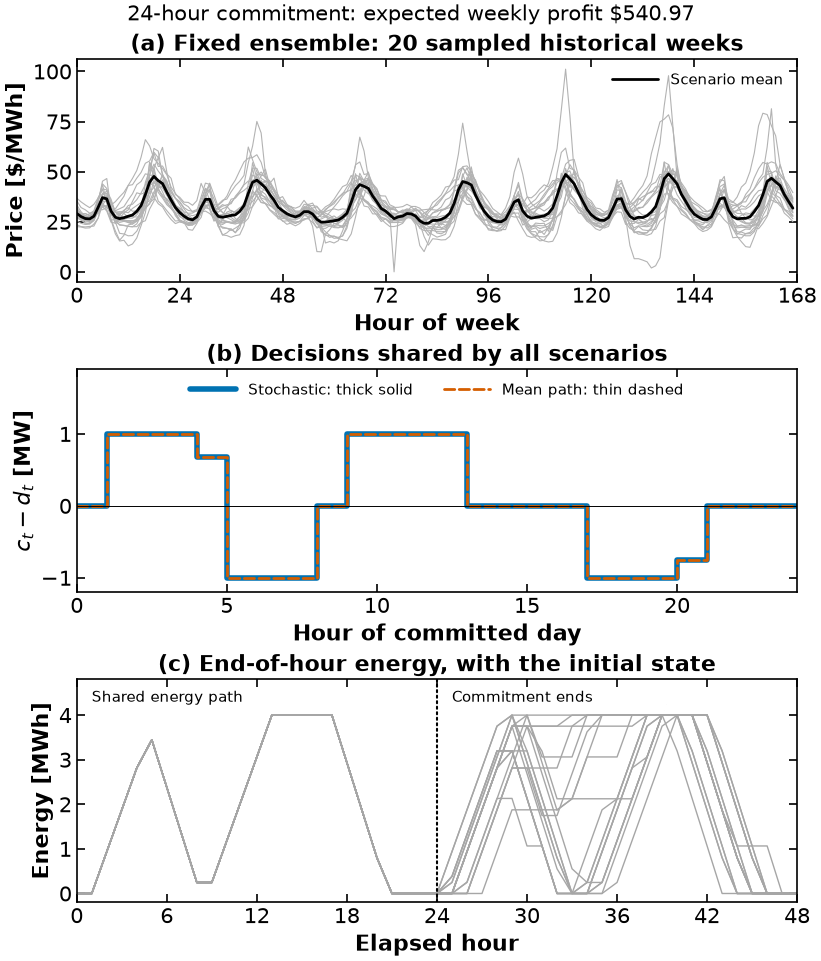

In [7]:
def plot_battery_stochastic_scenarios(results):
    """One fixed ensemble, two committed schedules, then recourse fan-out."""
    price = np.asarray(results["price_scenarios"])
    energy = np.asarray(results["energy"])
    n_commit = results["n_commit"]
    n_hours = results["hours_per_week"]
    horizon = results["hours_shown"]
    fig, axes = plt.subplots(3, 1, figsize=(8.2, 9.6), layout="constrained")
    ax_p, ax_u, ax_e = axes
    for scenario in price:
        ax_p.plot(np.arange(n_hours), scenario, color="0.70", lw=0.8, linestyle="-")
    ax_p.plot(np.arange(n_hours), price.mean(axis=0), color="black", lw=2,
              linestyle="-", label="Scenario mean")
    ax_p.set(xlim=(0, n_hours), ylabel="Price [$/MWh]", xlabel="Hour of week",
             title="(a) Fixed ensemble: 20 sampled historical weeks")
    ax_p.set_xticks(np.arange(0, n_hours + 1, 24))
    ax_p.legend(loc="upper right", fontsize=11)
    edges = np.arange(n_commit + 1)
    for key, color, linestyle, width, label in (
        ("net_here_and_now", "#0072B2", "-", 4, "Stochastic: thick solid"),
        ("net_deterministic", "#D55E00", "--", 2, "Mean path: thin dashed"),
    ):
        values = np.asarray(results[key])
        ax_u.step(edges, np.r_[values, values[-1]], where="post", color=color,
                  linestyle=linestyle, lw=width, label=label)
    ax_u.axhline(0, color="black", lw=0.7)
    ax_u.set(xlim=(0, n_commit), ylim=(-1.2, 1.9), ylabel="$c_t-d_t$ [MW]",
             xlabel="Hour of committed day", title="(b) Decisions shared by all scenarios")
    ax_u.legend(loc="upper center", ncol=2, fontsize=11)
    for scenario in energy:
        ax_e.plot(np.arange(horizon + 1), np.r_[results["E0"], scenario],
                  color="0.65", lw=1.0, linestyle="-")
    ax_e.axvline(n_commit, color="black", linestyle=":", lw=1.5)
    ax_e.text(n_commit + 1, 4.3, "Commitment ends", fontsize=11)
    ax_e.text(1, 4.3, "Shared energy path", fontsize=11)
    ax_e.set(xlim=(0, horizon), ylim=(-0.2, 4.8), ylabel="Energy [MWh]",
             xlabel="Elapsed hour", title="(c) End-of-hour energy, with the initial state")
    ax_e.set_xticks(np.arange(0, horizon + 1, 6))
    for ax in axes:
        ax.tick_params(colors="black")
        for spine in ax.spines.values():
            spine.set_color("black")
    fig.suptitle(f"24-hour commitment: expected weekly profit ${results['expected_profit']:.2f}",
                 fontsize=15)
    return fig


fig = plot_battery_stochastic_scenarios(results)
helper.save_figure(fig, "battery-stochastic-scenarios", quiet=True)
plt.show()

### Read the weekly comparison

* At $K=1$, the recourse model commits one charge/discharge pair. At $K=24$, all 24 pairs are shared. The figure shows $K=24$; it does not illustrate the one-hour count formula without changing $K$.
* During the committed day, every scenario has the same initial energy and actions, hence the same energy path. After that day, scenario recourse can separate. The vertical line is at **elapsed hour 24**; the last shared end-of-hour state occurs there.
* A coincident stochastic and mean-path schedule can give zero VSS on this instance. It does not establish that uncertain prices can always be replaced by their mean. Use the **evaluated recourse profits** in the table to determine VSS, rather than inferring it from the distance between schedules.
* Compare $K=1,6,24$ while keeping the same 20 weeks. More commitment reduces flexibility. Neither this controlled comparison nor the entire-year ensemble demonstrates a forecast's out-of-sample value.
* To study sampling sensitivity, change `WEEKLY_SEED` or `WEEKLY_SCENARIOS` and recompute both the information metrics and the expected-value evaluation. The fixed assertions document this 20-scenario example; update them for a new design. Do not select a seed after seeing profits and present it as a predictive validation.

For the hourly rolling policy and its inventory-adjusted evaluation, use the preceding sections. For the general information-value definitions and scenario-sampling theory, see [Stochastic Programming](SP.ipynb) and [Advanced Stochastic Programming](AdvancedTopics.ipynb).

## Interpretation limits and references

* At seven equally weighted scenarios and confidence 0.9, the lower-tail CVaR is the minimum scenario profit (tail mass 0.1 is less than 1/7).
* The comparison reports the exact lower-tail CVaR for this seven-scenario model, evaluated independently as the minimum scenario profit.
* The rolling oracle is a benchmark with a finite horizon and terminal constraint, not a proven globally optimal policy for the entire backtest.
* Birge and Louveaux (2011), 2nd ed., §§2.3–2.4, pp. 57–65; §§4.1–4.3, pp. 163–166.
* Rockafellar and Uryasev (2002), *Conditional Value-at-Risk for General Loss Distributions*.
